# Лабораторная работа №3

Номер по списку: **3**, ПК: **3**, группа: **2**.

Варианты таблиц выбираются по кругу: (номер−1) % число строк + 1. Для ЛР3–4 N=ПК+группа; N не является номером по списку.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats, special
import pywt
plt.rcParams.update({'figure.figsize': (12,4), 'figure.dpi': 100,
                     'axes.grid': True, 'grid.alpha': .25})
number=3; pc=3; group=2
rng=np.random.default_rng(303)


## Параметры сигнала и фильтров
$N=ПК+2$, $M=N\bmod10$, $L=N\bmod3$.
При L=0: видеоимпульс длительностью N нс; полосовой фильтр от $1/t_и$ до $2/t_и$.
При L=2: $x(t)=[1+0.5\cos(2\pi f_mt)]\cos(2\pi f_ct)$, $f_c=10N$ МГц, $f_m=\lfloor N/10\rfloor+M$ МГц; заградительный фильтр вырезает несущую.
Порядок прототипа n=4 и подавление Чебышёва II 40 дБ приняты, поскольку методичка их не задаёт. Итоговый порядок полосовых преобразований — 8. Для АМ ширина режекции выбрана $f_m/2$, чтобы сохранить боковые полосы.
Структура: **сигнал → БПФ → идеальная маска → ОБПФ**; параллельно **сигнал → SOS Баттерворта / SOS Чебышёва II**.

N=5, M=5, L=2, частоты фильтра [48.75 51.25] МГц
Cheby2 задан по задерживанию −40 дБ; Butterworth — по уровню −3 дБ.


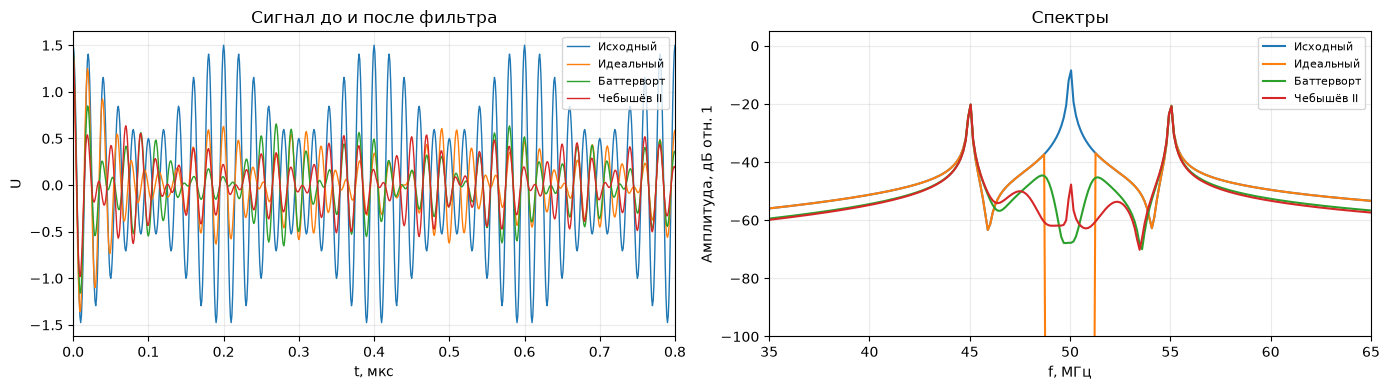

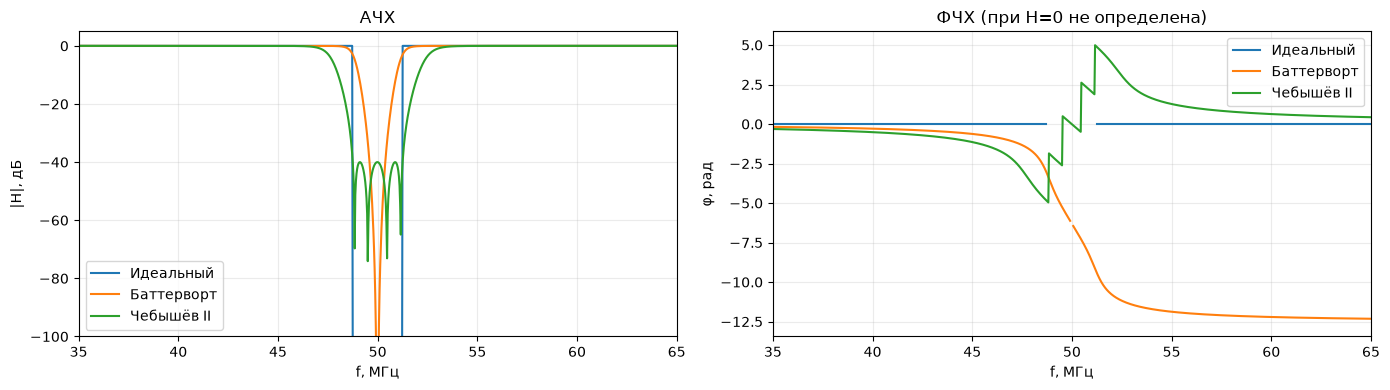

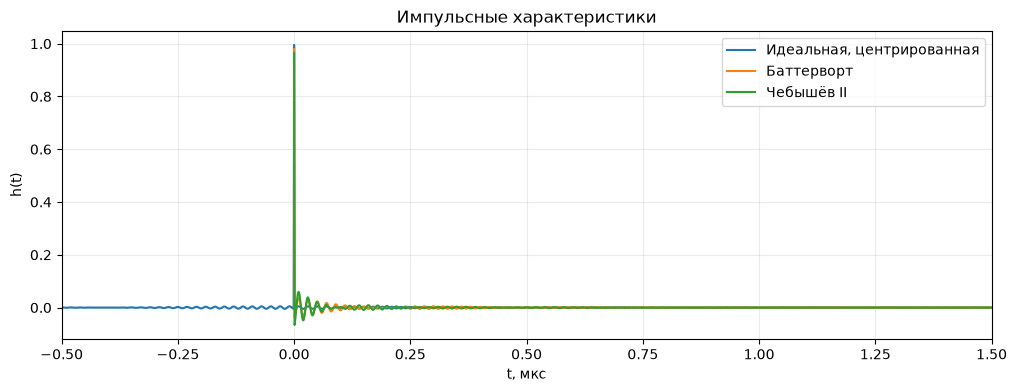

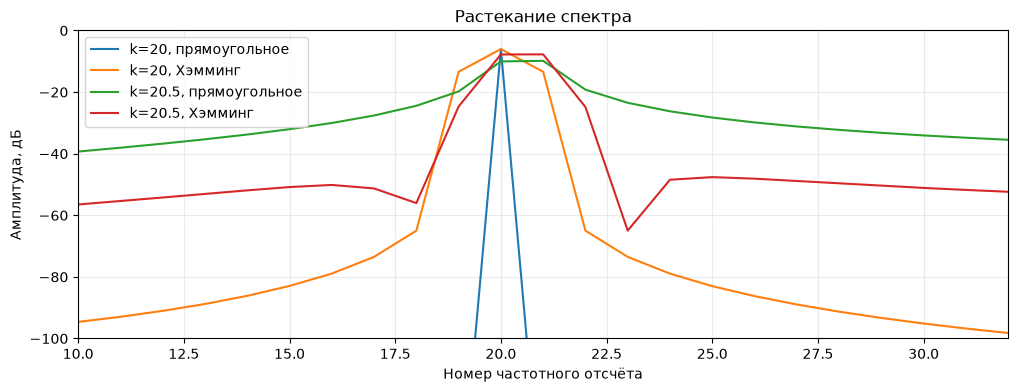

In [2]:
N=pc+group; M=N%10; L=N%3
if L==0:
    ti=N*1e-9; fs=4e9; length=8192; t=np.arange(length)/fs
    start=200e-9; x=((t>=start)&(t<start+ti)).astype(float)
    edges=np.array([1/ti,2/ti]); btype='bandpass'; plotlim=(180,300); tscale=1e9; tunit='нс'
else:
    fc=10*N*1e6; fm=(N//10+M)*1e6; fs=1e9; length=8192; t=np.arange(length)/fs
    x=(1+.5*np.cos(2*np.pi*fm*t))*np.cos(2*np.pi*fc*t)
    edges=np.array([fc-fm/4,fc+fm/4]); btype='bandstop'; plotlim=(0,.8); tscale=1e6; tunit='мкс'
f=np.fft.rfftfreq(length,1/fs)
inside=(f>=edges[0])&(f<=edges[1]); mask=inside if L==0 else ~inside
ideal=np.fft.irfft(np.fft.rfft(x)*mask,n=length)
sos_b=signal.butter(4,edges,btype=btype,fs=fs,output='sos')
# Для Cheby2 Wn — границы полосы задерживания, а не точки −3 дБ.
sos_c=signal.cheby2(4,40,edges,btype=btype,fs=fs,output='sos')
yb=signal.sosfilt(sos_b,x); yc=signal.sosfilt(sos_c,x)
print(f'N={N}, M={M}, L={L}, частоты фильтра {edges/1e6} МГц')
print('Cheby2 задан по задерживанию −40 дБ; Butterworth — по уровню −3 дБ.')
fig,axs=plt.subplots(1,2,figsize=(14,4))
for name,y in [('Исходный',x),('Идеальный',ideal),('Баттерворт',yb),('Чебышёв II',yc)]:
    axs[0].plot(t*tscale,y,label=name,lw=1)
    amp=np.abs(np.fft.rfft(y))/length
    axs[1].plot(f/1e6,20*np.log10(np.maximum(amp,1e-10)),label=name)
axs[0].set(xlabel='t, '+tunit,ylabel='U',xlim=plotlim,title='Сигнал до и после фильтра')
axs[1].set(xlabel='f, МГц',ylabel='Амплитуда, дБ отн. 1',title='Спектры',xlim=((0,500) if L==0 else (fc/1e6-3*fm/1e6,fc/1e6+3*fm/1e6)),ylim=(-100,5))
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
w=np.linspace(0,fs/2,16000)
_,hb=signal.sosfreqz(sos_b,worN=w,fs=fs); _,hc=signal.sosfreqz(sos_c,worN=w,fs=fs)
passmask=(w>=edges[0])&(w<=edges[1]); hi=(passmask if L==0 else ~passmask).astype(float)
fig,axs=plt.subplots(1,2,figsize=(14,4))
for name,h in [('Идеальный',hi.astype(complex)),('Баттерворт',hb),('Чебышёв II',hc)]:
    axs[0].plot(w/1e6,20*np.log10(np.maximum(np.abs(h),1e-6)),label=name)
    ph=np.unwrap(np.angle(h)); ph[np.abs(h)<1e-5]=np.nan
    axs[1].plot(w/1e6,ph,label=name)
for ax in axs: ax.set(xlabel='f, МГц',xlim=((0,500) if L==0 else (fc/1e6-3*fm/1e6,fc/1e6+3*fm/1e6))); ax.legend()
axs[0].set(ylabel='|H|, дБ',ylim=(-100,5),title='АЧХ'); axs[1].set(ylabel='φ, рад',title='ФЧХ (при H=0 не определена)')
plt.tight_layout(); plt.show()
imp=np.zeros(length); imp[0]=1
h0=np.fft.fftshift(np.fft.irfft(mask.astype(float),n=length))
hb0=signal.sosfilt(sos_b,imp); hc0=signal.sosfilt(sos_c,imp)
fig,ax=plt.subplots()
ax.plot((np.arange(length)-length//2)/fs*tscale,h0,label='Идеальная, центрированная')
ax.plot(t*tscale,hb0,label='Баттерворт'); ax.plot(t*tscale,hc0,label='Чебышёв II')
ax.set(xlabel='t, '+tunit,ylabel='h(t)',title='Импульсные характеристики',xlim=((-80,160) if L==0 else (-.5,1.5))); ax.legend(); plt.show()
# Растекание спектра: целое и дробное число периодов, с окном и без.
n=np.arange(256); fig,ax=plt.subplots()
for k in [20,20.5]:
    for win,label in [(np.ones(256),'прямоугольное'),(np.hamming(256),'Хэмминг')]:
        a=np.abs(np.fft.rfft(np.cos(2*np.pi*k*n/256)*win))/win.sum()
        ax.plot(np.arange(len(a)),20*np.log10(np.maximum(a,1e-8)),label=f'k={k}, {label}')
ax.set(xlabel='Номер частотного отсчёта',ylabel='Амплитуда, дБ',xlim=(10,32),ylim=(-100,0),title='Растекание спектра'); ax.legend(); plt.show()

## Выводы
Идеальная маска резко ограничивает спектр, но её ИХ двусторонняя и бесконечная: отклик до воздействия означает некаузальность. БПФ реализует циклическую свёртку на конечной записи, что требует осторожности с границами. БИХ-фильтры каузальны, имеют переходную полосу, нелинейную фазу и затухающую ИХ. В начале записи наблюдается переходный процесс.
Баттерворт имеет монотонную АЧХ, Чебышёв II — пульсации в полосе задерживания и нули передачи; одинаковые численные Wn у них задают разные уровни. На частотах нулей передачи фаза не определена.
Для видеоимпульса полосовая фильтрация подавляет постоянную составляющую и формирует колебательный отклик. Для АМ заградительный фильтр подавляет несущую, оставляя две боковые полосы. Окно Хэмминга уменьшает боковые лепестки при расширении главного; дробное число периодов даёт растекание спектра.